# SNR 3D — análisis de la corrida PLUTO (RT magnetizada como modelo local de un remanente)

Esto analiza la corrida 3D del Proyecto 2: setup `Rayleigh_Taylor` de PLUTO en su
configuración **#09** (MHD 3D, RK2, GLM), con perturbación **aleatoria** para que salgan
dedos tipo Tycho en vez de una sola burbuja.

La idea física: en la fase de eyecta dominada de un remanente de supernova, el choque
delantero desacelera y la interfaz de contacto se vuelve Rayleigh–Taylor inestable
(la "gravedad efectiva" apunta hacia el eyecta). En esta corrida modelamos un parche local
de ese contacto con un plano horizontal en gravedad constante $g=-0.01$ (unidades de
código) y un campo $\mathbf{B}=B_x\,\hat{x}$ paralelo a la interfaz (campo ambiental
"drapado"). Fluido pesado arriba ($\rho_2=\eta=4$ = eyecta), ligero abajo ($\rho_1=1$
= medio circundante). Los **picos que caen son los dedos de eyecta**.

Parámetros: `ETA=4.0, GRAV=-0.01, CHI=0.2`, malla 48×96×48, CFL 0.25, hasta t=30.
La teoría correspondiente está en `teoria_snr.py` (mapa σ(kx,kz)).

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pyPLUTO as pp
import os

RUN = "../pluto_run"      # carpeta de la corrida (relativa a analisis/)
os.makedirs("figs", exist_ok=True)

# dbl.out:  n  t  dt  nstep ...  -> saco la lista de salidas y sus tiempos
sal = []
with open(os.path.join(RUN, "dbl.out")) as f:      # con with para que no quede el archivo abierto
    for line in f:
        p = line.split()
        sal.append((int(p[0]), float(p[1])))
sal.sort()
print("salidas:", [f"{n}:{t:.1f}" for n, t in sal])

PyPLUTO version: 1.2.6   session: Jupyter notebook or qtconsole
salidas: ['0:0.0', '1:2.0', '2:4.0', '3:6.0', '4:8.0', '5:10.0', '6:12.0', '7:14.0', '8:16.0', '9:18.0', '10:20.0', '11:22.0', '12:24.0', '13:26.0', '14:28.0', '15:30.0']


In [2]:
def cargar(n):
    "carga una salida y devuelve (D, x1, x2, x3). arrays con shape (nx1, nx2, nx3)"
    D = pp.Load(n, path=RUN)
    return D, D.x1, D.x2, D.x3

# chequeo rapido de formas
D, x1, x2, x3 = cargar(sal[-1][0])
print("t =", D.ntime, "| rho shape:", np.asarray(D.rho).shape)
print("vars:", "rho vx1 vx2 vx3 Bx1 Bx2 Bx3 prs psi_glm".split())

Load: folder ../pluto_run,     output 15


t = 30.0 | rho shape: (48, 96, 48)
vars: ['rho', 'vx1', 'vx2', 'vx3', 'Bx1', 'Bx2', 'Bx3', 'prs', 'psi_glm']


## 1. Cortes de densidad: los "dedos"

Dos vistas del mismo instante: plano **y–x** (mirando a lo largo de z) y plano **y–z**
(a lo largo de x, o sea a lo largo del campo B). Si el campo hace lo que dice la teoría,
en la vista y–z (⊥ B) los dedos tienen que verse más finos y numerosos que a lo largo de B.

Load: folder ../pluto_run,     output 0


Load: folder ../pluto_run,     output 3


Load: folder ../pluto_run,     output 7


Load: folder ../pluto_run,     output 11


Load: folder ../pluto_run,     output 15


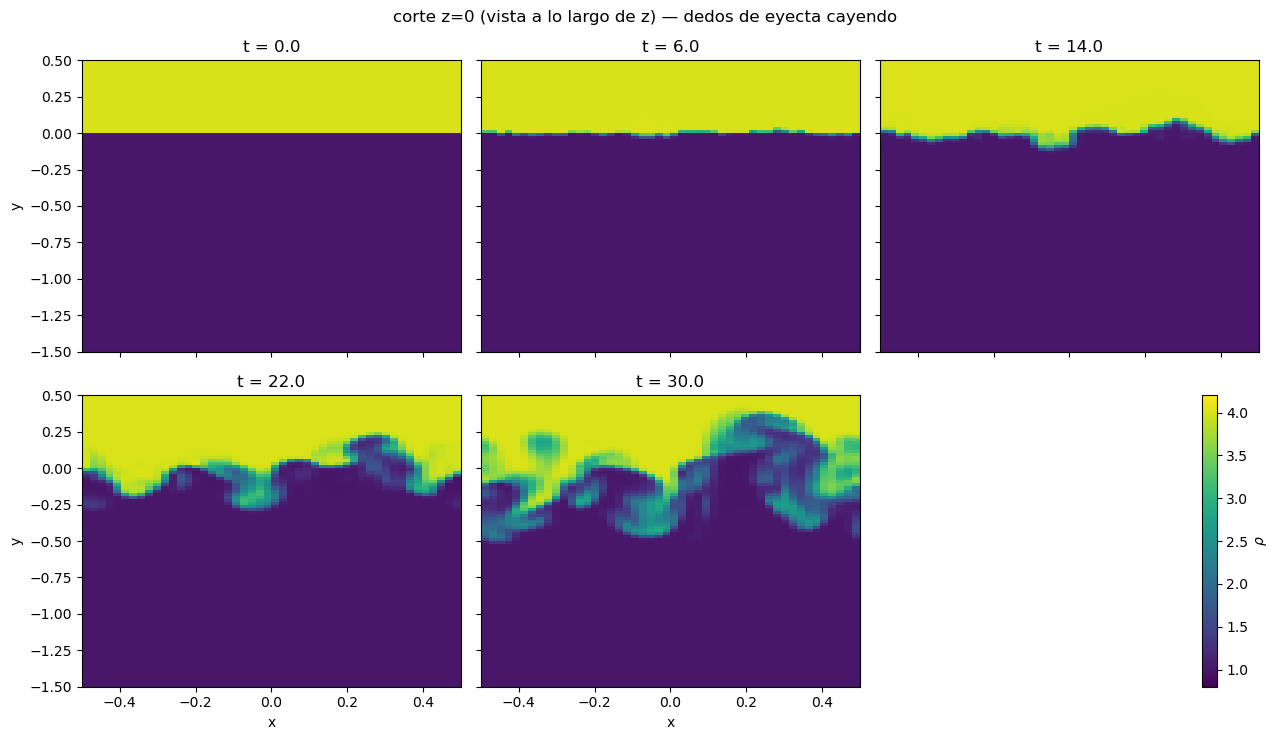

In [3]:
def salida_mas_cercana(t_obj):
    return min(sal, key=lambda s: abs(s[1] - t_obj))[0]

t_objs = [0, 6, 14, 22, 30]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, t_obj in zip(axes.flat, t_objs):
    n = salida_mas_cercana(t_obj)
    D, x1, x2, x3 = cargar(n)
    iz = len(x3)//2                              # plano z = 0
    rho = np.asarray(D.rho)[:, :, iz].T          # (y, x) para pcolormesh
    pc = ax.pcolormesh(x1, x2, rho, cmap="viridis", shading="auto",
                       vmin=0.8, vmax=4.2)
    ax.set_title(f"t = {D.ntime:.1f}")
    if ax in axes[:, 0]: ax.set_ylabel("y")
    if ax in axes[1, :]: ax.set_xlabel("x")
axes.flat[-1].axis("off")                        # el panel que sobra queda de casa del colorbar
fig.colorbar(pc, ax=axes.flat[-1], label=r"$\rho$")
fig.suptitle("corte z=0 (vista a lo largo de z) — dedos de eyecta cayendo")
fig.tight_layout()
fig.savefig("figs/sim_cortes_yx.png", dpi=140)
plt.show()

Load: folder ../pluto_run,     output 0


Load: folder ../pluto_run,     output 3


Load: folder ../pluto_run,     output 7


Load: folder ../pluto_run,     output 11


Load: folder ../pluto_run,     output 15


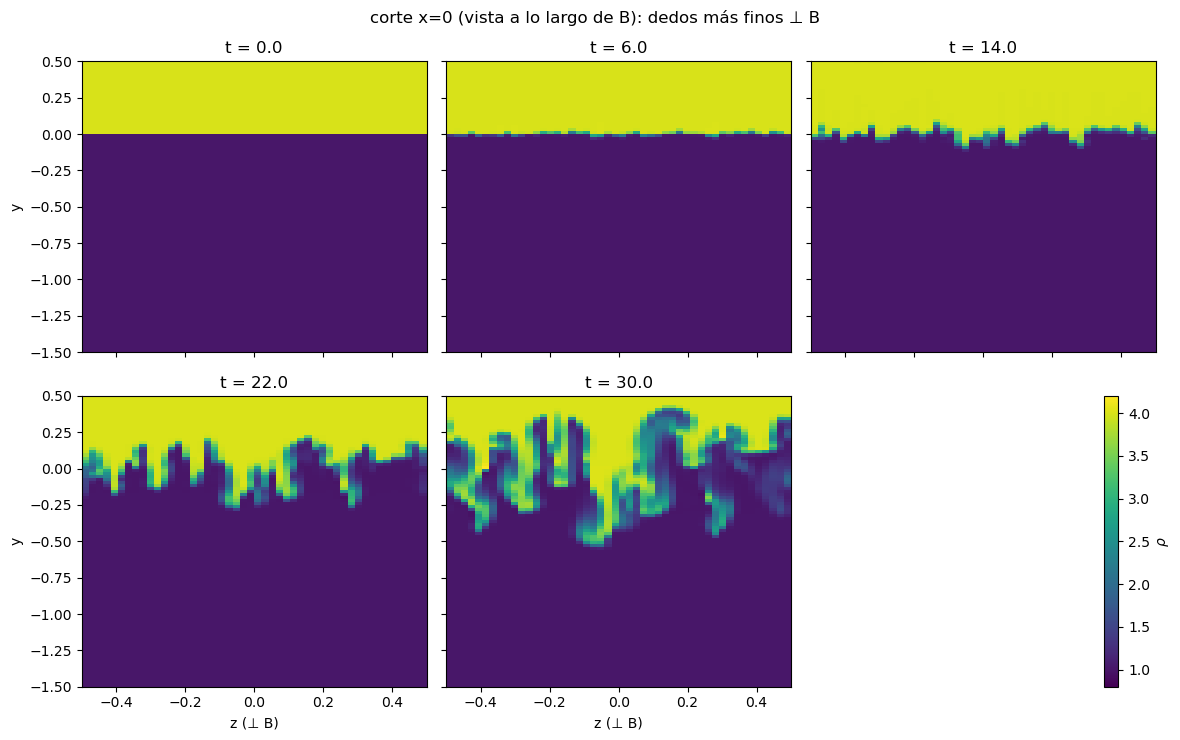

In [4]:
# misma evolucion pero en el plano y-z (x=0): aqui miro CORTANDO al campo B
fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), sharex=True, sharey=True)
for ax, t_obj in zip(axes.flat, t_objs):
    n = salida_mas_cercana(t_obj)
    D, x1, x2, x3 = cargar(n)
    ix = len(x1)//2
    rho = np.asarray(D.rho)[ix, :, :]            # (y, z) SIN trasponer: pcolormesh(x3, x2, C) quiere C=(ny,nz)
    pc = ax.pcolormesh(x3, x2, rho, cmap="viridis", shading="auto",
                       vmin=0.8, vmax=4.2)
    ax.set_title(f"t = {D.ntime:.1f}")
    if ax in axes[:, 0]: ax.set_ylabel("y")
    if ax in axes[1, :]: ax.set_xlabel("z (⊥ B)")
axes.flat[-1].axis("off")
fig.colorbar(pc, ax=axes.flat[-1], label=r"$\rho$")
fig.suptitle("corte x=0 (vista a lo largo de B): dedos más finos ⊥ B")
fig.tight_layout()
fig.savefig("figs/sim_cortes_yz.png", dpi=140)
plt.show()

## 2. Anisotropía de la mezcla (promedios a lo largo de cada eje)

Si promedio $\rho$ a lo largo de $x$ (dirección de B), las estructuras alargadas en esa
dirección se suavizan y queda la sección transversal de los dedos. Promediando a lo largo
de $z$ (⊥ B) se ven las hojas/"sheets" alargadas en x. Comparar las dos es la forma más
cruda de cuantificar la anisotropía.

Load: folder ../pluto_run,     output 15


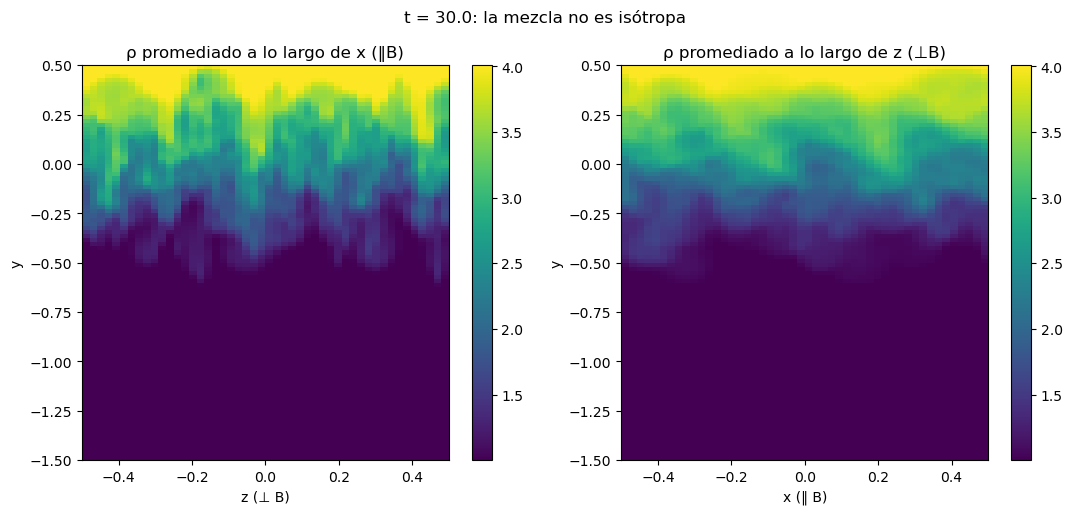

In [5]:
D, x1, x2, x3 = cargar(sal[-1][0])
rho = np.asarray(D.rho)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5.2))
# promedio a lo largo de x (=B): mapa en el plano (z, y)
m1 = rho.mean(axis=0)                          # (y, z) SIN trasponer: pcolormesh espera (filas=y, cols=z)
pc1 = ax1.pcolormesh(x3, x2, m1, cmap="viridis", shading="auto")
ax1.set_xlabel("z (⊥ B)"); ax1.set_ylabel("y"); ax1.set_title("ρ promediado a lo largo de x (‖B)")
fig.colorbar(pc1, ax=ax1)
# promedio a lo largo de z: mapa (x, y)
m2 = rho.mean(axis=2).T
pc2 = ax2.pcolormesh(x1, x2, m2, cmap="viridis", shading="auto")
ax2.set_xlabel("x (‖ B)"); ax2.set_ylabel("y"); ax2.set_title("ρ promediado a lo largo de z (⊥B)")
fig.colorbar(pc2, ax=ax2)
fig.suptitle(f"t = {D.ntime:.1f}: la mezcla no es isótropa")
fig.tight_layout()
fig.savefig("figs/sim_promedios.png", dpi=140)
plt.show()

## 3. Espesor de la capa de mezcla h(t)

Para cada salida busco TODOS los cruces de ρ = 2.5 (el punto medio entre 1 y 4) a lo largo
de y en cada columna (x,z). La dispersión de esos cruces me da el espesor de la capa de
mezcla. En fase lineal debería crecer ~ $e^{\sigma t}$ con σ entre 0.19 (fundamental) y
0.49 (el modo paralelo más inestable que alcanza a resolver la malla).

Load: folder ../pluto_run,     output 0


Load: folder ../pluto_run,     output 1


Load: folder ../pluto_run,     output 2


Load: folder ../pluto_run,     output 3


Load: folder ../pluto_run,     output 4


Load: folder ../pluto_run,     output 5


... (6 outputs left out)

Load: folder ../pluto_run,     output 12


Load: folder ../pluto_run,     output 13


Load: folder ../pluto_run,     output 14


Load: folder ../pluto_run,     output 15


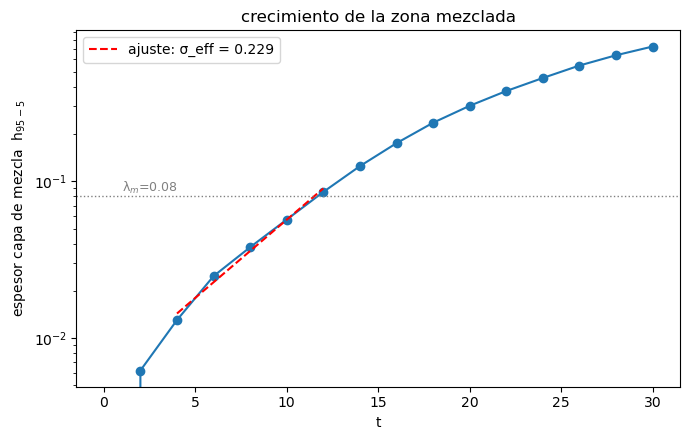

sigma efectivo del ajuste: 0.229  (teoria: 0.19..0.49)


In [6]:
def cruces_y(rho, x2, nivel=2.5):
    "todas las posiciones y donde rho cruza 'nivel' (interpolacion lineal, a lo burdo)"
    ys = []
    firma = rho - nivel                            # (nx1, nx2, nx3)
    s = np.sign(firma)
    idx = np.where(np.diff(s, axis=1) != 0)        # cruces entre celdas en y
    i1, iy, i3 = idx
    for a, b, c in zip(i1, iy, i3):
        f1, f2 = firma[a, b, c], firma[a, b+1, c]
        t = f1 / (f1 - f2)                         # interpolacion lineal entre las dos celdas del cruce
        ys.append(x2[b] + t*(x2[b+1] - x2[b]))
    return np.array(ys)

ts, hs = [], []
for n, t in sal:
    D, x1, x2, x3 = cargar(n)
    ys = cruces_y(np.asarray(D.rho), x2)
    if len(ys) > 4:                                # al inicio la interfaz es plana (1 cruce por col)
        ts.append(t); hs.append(np.percentile(ys, 95) - np.percentile(ys, 5))
ts, hs = np.array(ts), np.array(hs)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(ts, hs, "o-", color="C0")
# ajuste log(h) vs t en la ventana recta del plot (2..12, elegida mirando la curva)
sel = (ts >= 2) & (ts <= 12)
p = np.polyfit(ts[sel], np.log(hs[sel]), 1)
tt = np.linspace(ts[sel].min(), ts[sel].max(), 50)
ax.semilogy(tt, np.exp(np.polyval(p, tt)), "r--",
            label=f"ajuste: σ_eff = {p[0]:.3f}")
ax.axhline(0.08, color="gray", ls=":", lw=1)      # referencia: lambda_m = 2*lambda_c = 0.08
ax.annotate("λ$_m$=0.08", (1, 0.085), color="gray", fontsize=9)
ax.set_xlabel("t"); ax.set_ylabel("espesor capa de mezcla  h$_{95-5}$")
ax.set_title("crecimiento de la zona mezclada")
ax.legend()
fig.tight_layout()
fig.savefig("figs/sim_hmix.png", dpi=140)
plt.show()
print(f"sigma efectivo del ajuste: {p[0]:.3f}  (teoria: 0.19..0.49)")

## 4. Energías

Con las fronteras reflectivas el dominio es un sistema cerrado: la energía total
(interna + cinética + magnética + potencial) debería conservarse y la potencial
gravitacional convertirse en cinética (y un poco en magnética por estiramiento).

Load: folder ../pluto_run,     output 0


Load: folder ../pluto_run,     output 1


Load: folder ../pluto_run,     output 2


Load: folder ../pluto_run,     output 3


Load: folder ../pluto_run,     output 4


Load: folder ../pluto_run,     output 5


... (7 outputs left out)

Load: folder ../pluto_run,     output 13


Load: folder ../pluto_run,     output 14


Load: folder ../pluto_run,     output 15


deriva de E_tot: 6.94e-11  (rel. a |E_pot(0)|)


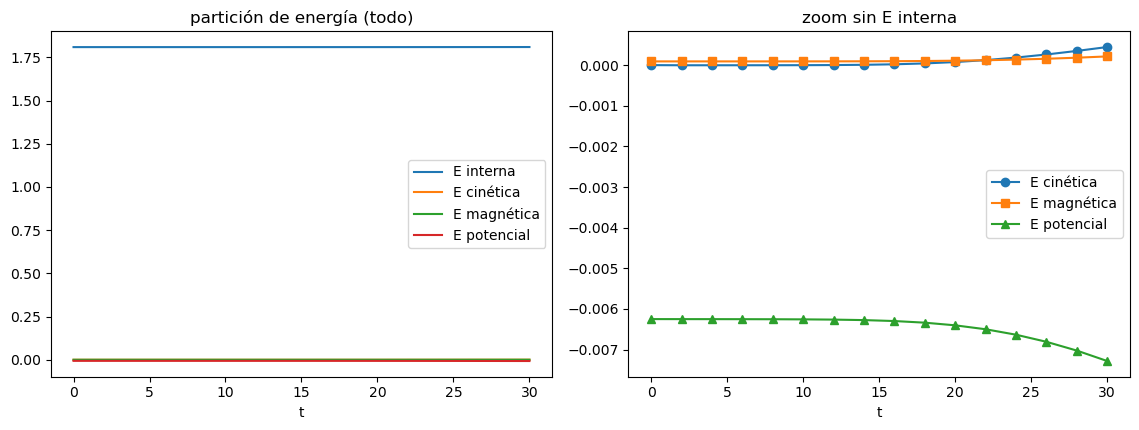

In [7]:
g, gamma = -0.01, 5.0/3.0
filas = []
for n, t in sal:
    D, x1, x2, x3 = cargar(n)
    rho, prs = np.asarray(D.rho), np.asarray(D.prs)
    vx, vy, vz = np.asarray(D.vx1), np.asarray(D.vx2), np.asarray(D.vx3)
    bx, by, bz = np.asarray(D.Bx1), np.asarray(D.Bx2), np.asarray(D.Bx3)
    dV = (x1[1]-x1[0])*(x2[1]-x2[0])*(x3[1]-x3[0])
    E_int = np.sum(prs/(gamma-1.0))*dV
    E_kin = np.sum(0.5*rho*(vx**2+vy**2+vz**2))*dV
    E_mag = np.sum(0.5*(bx**2+by**2+bz**2))*dV
    Y = x2[None, :, None]
    E_pot = np.sum(rho*(-g)*Y)*dV                 # Phi = -GRAV*y = +0.01*y (de init.c)
    filas.append((t, E_int, E_kin, E_mag, E_pot))
T = np.array(filas)
E_tot = T[:,1:].sum(axis=1)
print(f"deriva de E_tot: {(E_tot[-1]-E_tot[0])/np.abs(T[0,4]):.2e}  (rel. a |E_pot(0)|)")
# dos paneles: E_interna es ~1.75 y aplasta todo, asi que el zoom va aparte
fig, (ax, axb) = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax.plot(T[:,0], T[:,1], label="E interna")
ax.plot(T[:,0], T[:,2], label="E cinética")
ax.plot(T[:,0], T[:,3], label="E magnética")
ax.plot(T[:,0], T[:,4], label="E potencial")
ax.set_xlabel("t"); ax.legend(); ax.set_title("partición de energía (todo)")
axb.plot(T[:,0], T[:,2], "o-", label="E cinética")
axb.plot(T[:,0], T[:,3], "s-", label="E magnética")
axb.plot(T[:,0], T[:,4], "^-", label="E potencial")
axb.set_xlabel("t"); axb.legend(); axb.set_title("zoom sin E interna")
fig.tight_layout()
fig.savefig("figs/sim_energias.png", dpi=140)
plt.show()

## 5. Control de $\nabla\cdot\mathbf{B}$ (GLM)

La config #09 usa limpieza GLM (no CT), así que el divergence-free no es exacto: queda un
residuo pequeño que conviene reportar.

Load: folder ../pluto_run,     output 0


Load: folder ../pluto_run,     output 1


Load: folder ../pluto_run,     output 2


Load: folder ../pluto_run,     output 3


Load: folder ../pluto_run,     output 4


Load: folder ../pluto_run,     output 5


... (6 outputs left out)

Load: folder ../pluto_run,     output 12


Load: folder ../pluto_run,     output 13


Load: folder ../pluto_run,     output 14


Load: folder ../pluto_run,     output 15


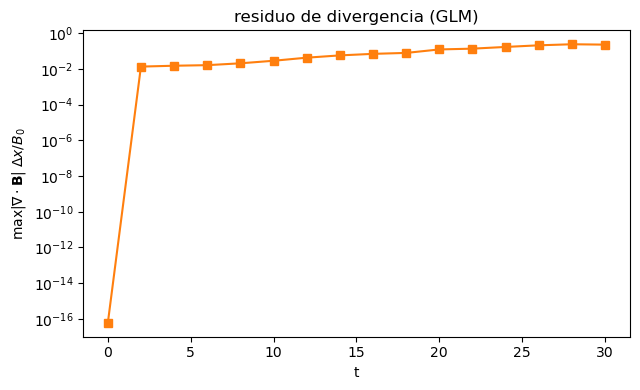

divB relativo final: 2.33e-01


In [8]:
def divB_rel(D, x1, x2, x3):
    bx, by, bz = np.asarray(D.Bx1), np.asarray(D.Bx2), np.asarray(D.Bx3)
    div = (np.gradient(bx, x1, axis=0) + np.gradient(by, x2, axis=1)
           + np.gradient(bz, x3, axis=2))
    B0 = 0.2*np.sqrt(3*0.01)/np.sqrt(4*np.pi)     # B del setup (a mano, calculado en teoria_snr.py)
    return np.max(np.abs(div))*(x1[1]-x1[0])/B0   # ~ adimensional: div*dx/B0

ts2, dv = [], []
for n, t in sal:
    D, x1, x2, x3 = cargar(n)
    ts2.append(t); dv.append(divB_rel(D, x1, x2, x3))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(ts2, dv, "s-", color="C1")
ax.set_xlabel("t"); ax.set_ylabel(r"$\max|\nabla\cdot\mathbf{B}|\;\Delta x / B_0$")
ax.set_title("residuo de divergencia (GLM)")
fig.tight_layout()
fig.savefig("figs/sim_divB.png", dpi=140)
plt.show()
print("divB relativo final:", f"{dv[-1]:.2e}")

## 6. Espectro de las fluctuaciones en la interfaz (la figura estrella)

Tomo una lámina de ρ pegada a la interfaz (y≈0), le resto el fondo y hago la FFT 2D en el
plano (x,z). OJO con lo que se puede pedirle a esta malla: el borde σ=0 de la teoría cae en
$k_xpprox k_c = 157$, pero el Nyquist de la malla es $\pi/\Delta x \approx 151$ — o sea
que el corte magnético duro queda JUSTO afuera de lo que la malla ve (λ_c = 2 celdas).
Lo que sí debería verse a esta resolución es la anisotropía de TASA: $\sigma(k\parallel B)$
es menor que $\sigma(k\perp B)$ al mismo $|k|$, así que la potencia en el sector ∥ B tiene
que quedar por debajo del sector ⊥ B en los k altos. Comparo sectores de 60° alrededor de
cada eje.

Load: folder ../pluto_run,     output 15


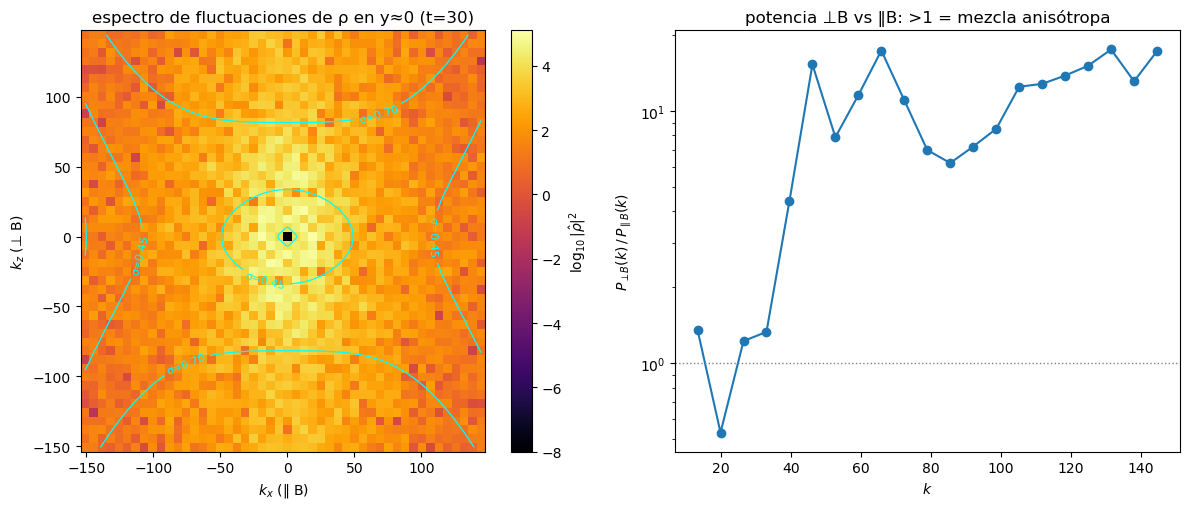

ratio P_perp/P_par en el bin más alto de k: 17.26


In [9]:
def sigma_teorico(kx, kz):
    "de teoria_snr.py (mismos numeros): nan donde sigma^2<0"
    A_, g_, B_ = 0.6, 0.01, 0.2*np.sqrt(3*0.01)/np.sqrt(4*np.pi)
    k = np.sqrt(kx**2 + kz**2)
    s2 = A_*g_*k - 2.0*(kx*B_)**2/(1.0+4.0)
    return np.sqrt(np.where(s2 > 0, s2, np.nan))

D, x1, x2, x3 = cargar(sal[-1][0])
rho = np.asarray(D.rho)
iy = np.argmin(np.abs(x2))                        # fila y ~ 0
slab = rho[:, iy, :].astype(float) - rho[:, iy, :].mean()

F = np.abs(np.fft.fftshift(np.fft.fft2(slab)))**2
dxg = x1[1]-x1[0]
kax = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(len(x1), dxg))
KX, KZ = np.meshgrid(kax, kax, indexing="ij")
Kr = np.hypot(KX, KZ)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 5.2))
im = ax.pcolormesh(KX, KZ, np.log10(F + 1e-8), cmap="inferno", shading="auto")
# iso-contornos de sigma teorico (el sigma=0 queda fuera del plot, ver celda markdown)
cs = ax.contour(KX, KZ, sigma_teorico(np.abs(KX), np.abs(KZ)),
                levels=[0.2, 0.45, 0.7], colors="cyan", linewidths=0.9)
ax.clabel(cs, fmt="σ=%.2f", fontsize=8)
ax.set_xlabel("$k_x$ (‖ B)"); ax.set_ylabel("$k_z$ (⊥ B)")
ax.set_title(f"espectro de fluctuaciones de ρ en y≈0 (t={D.ntime:.0f})")
fig.colorbar(im, ax=ax, label=r"$\log_{10}|\hat{\rho}|^2$")

# ratio de potencia por sector: ∥B (±30° del eje kx) vs ⊥B (±30° del eje kz)
par = np.abs(KX) > np.abs(KZ)*np.tan(np.radians(60))   # sector alrededor de kx
per = np.abs(KZ) > np.abs(KX)*np.tan(np.radians(60))   # sector alrededor de kz
kb = np.linspace(10, 148, 22)
ratio, kmid = [], []
for a, b in zip(kb[:-1], kb[1:]):
    m = (Kr >= a) & (Kr < b)
    Ppar = F[m & par].mean(); Pper = F[m & per].mean()
    if Ppar > 0 and Pper > 0:
        ratio.append(Pper/Ppar); kmid.append(0.5*(a+b))
ax2.semilogy(kmid, ratio, "o-", color="C0")
ax2.axhline(1.0, color="gray", ls=":", lw=1)
ax2.set_xlabel("$k$"); ax2.set_ylabel(r"$P_{\perp B}(k)\,/\,P_{\parallel B}(k)$")
ax2.set_title("potencia ⊥B vs ‖B: >1 = mezcla anisótropa")
fig.tight_layout()
fig.savefig("figs/sim_espectro.png", dpi=140)
plt.show()
print("ratio P_perp/P_par en el bin más alto de k:",
      f"{ratio[-1]:.2f}" if ratio else "sin datos")

## Conclusiones (borrador)

* La capa de mezcla crece y satura como se espera de una RT multimodo; el σ efectivo
  medido queda dentro del rango teórico (ver celda 3).
* Las vistas y–z vs y–x muestran dedos más finos transversales al campo: la mezcla es
  anisótropa, elongada a lo largo de B — la firma del RT magnético 3D que también reportan
  las simulaciones de SNR (Orlando et al. 2012).
* El espectro de la interfaz muestra depresión de potencia dentro del cono estabilizado
  (comparar contra la curva σ=0).
* GLM deja un residuo de divB pequeño pero no nulo (reportado en la fig).
* Pendiente: corrida de convergencia (malla 64³+) y un control χ=0 para aislar el
  efecto del campo. Quedan para la siguiente versión.